# MOMENT SageMaker Model

## 1. Set up the environment

Install the dependencies.

In [1]:
%pip install --quiet "sagemaker==3.30.0" plotly nbformat kaleido


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Install Chrome, which `kaleido` uses to render the figures as static images.

In [2]:
import plotly.io as pio

pio.get_chrome()
pio.renderers.default = "png"

Set up the environment. 

In [3]:
import io
import time
import datetime
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.core.resources import Model, TransformJob, EndpointConfig, Endpoint
from sagemaker.core.shapes import (
    ContainerDefinition,
    TransformInput,
    TransformDataSource,
    TransformS3DataSource,
    TransformOutput,
    TransformResources,
    ProductionVariant,
    AsyncInferenceConfig,
    AsyncInferenceOutputConfig,
)

# SageMaker session
session = Session()

# SageMaker role
role = get_execution_role()

# S3 bucket
bucket = "sagemaker-moment-anomaly-detection"

# EC2 instance
instance_type = "ml.g4dn.12xlarge"

# AWS account ID
account = session.account_id()

# AWS region
region = session.boto_region_name

# Model ECR image
ecr_uri = f"{account}.dkr.ecr.{region}.amazonaws.com/sagemaker-moment-anomaly-detection:latest"

# Model S3 URI
s3_uri = f"s3://{bucket}/moment-1-large/model.tar.gz"

# Suffix for the names of the model, the batch transform job and the endpoints
suffix = datetime.datetime.now().strftime("%Y-%m-%d-%H-%M-%S")

Define a function for plotting the time series. 

In [4]:
def plot(
        df: pd.DataFrame,
        highlight_steps: int = 48,
        plot_width: int = 800,
        subplot_height: int = 240,
) -> go.Figure:
    """
    Input:
        df              : long-format data frame with id, timestamp, value, and optionally reconstruction
        highlight_steps : width of the band centred on each time series' largest squared reconstruction error,
                          in time steps (0 for no band)
    Output:
        plotly Figure, one subplot per time series
    """
    # Color scheme
    TEXT = "#24292f"  # text
    LINE = "#cecece"  # axis lines
    GRID = "#e8e8e8"  # grid lines
    OBSERVED = "#838383"  # observed values
    RECONSTRUCTED = "#0588F0"  # reconstruction
    HIGHLIGHT = "#FFF7C2"  # band around the largest reconstruction error

    # One group per time series, sorted by id, with its rows in time order
    groups = df.sort_values("timestamp").groupby("id")

    fig = make_subplots(rows=groups.ngroups, cols=1, shared_xaxes=True, vertical_spacing=0.04)

    for row, (id, g) in enumerate(groups, start=1):
        first = row == 1  # show each legend entry once

        # Observed values, and the reconstruction if there is one
        for column, name, color, width in [
            ("value", "Observed", OBSERVED, 0.5),
            ("reconstruction", "Reconstruction", RECONSTRUCTED, 1),
        ]:
            if column not in g:
                continue
            fig.add_scatter(
                x=g["timestamp"],
                y=g[column],
                mode="lines",
                name=name,
                legendgroup=name,
                showlegend=first,
                line=dict(color=color, width=width),
                row=row,
                col=1,
            )

        # Band of `highlight_steps` time steps centred on the largest squared
        # reconstruction error, cut at the ends of the series, if there is a reconstruction
        if "reconstruction" in g and highlight_steps > 0:
            squared_error = (g["value"] - g["reconstruction"]) ** 2
            peak = squared_error.to_numpy().argmax()
            start = max(peak - highlight_steps // 2, 0)
            end = min(peak + highlight_steps // 2, len(g) - 1)

            # Half-width of the band in hours, from the time step of the series
            step = g["timestamp"].iloc[1] - g["timestamp"].iloc[0]
            hours = (highlight_steps // 2) * step / pd.Timedelta(hours=1)

            fig.add_vrect(
                x0=str(g["timestamp"].iloc[start]),
                x1=str(g["timestamp"].iloc[end]),
                fillcolor=HIGHLIGHT,
                line_width=0,
                layer="below",
                name=f"Largest reconstruction error ± {hours:g}h",
                legendgroup="Largest reconstruction error",
                showlegend=first,
                row=row,
                col=1,
            )

    # Same style for all axes
    axes = dict(mirror=True, linecolor=LINE, gridcolor=GRID, gridwidth=0.5, tickfont=dict(color=TEXT))
    fig.update_xaxes(type="date", tickformat="%b %d<br>(%a) %Y", tickangle=0, **axes)
    fig.update_yaxes(tickformat=",.0f", zeroline=False, **axes)

    fig.update_layout(
        width=plot_width,
        height=subplot_height * groups.ngroups + 100,
        paper_bgcolor="white",
        plot_bgcolor="white",
        margin=dict(t=50, b=50, l=50, r=50),
        legend=dict(
            x=0,
            y=1.0,
            yanchor="bottom",
            orientation="h",
            bgcolor="rgba(0,0,0,0)",
            font=dict(color=TEXT, size=14),
        ),
    )
    return fig

## 2. Upload the data to S3

Load the sample data.

In [5]:
dataset = pd.read_csv("sample_data/data.csv", parse_dates=["timestamp"])

In [6]:
dataset.shape

(3000, 3)

In [7]:
dataset.head()

,id,timestamp,value
0,A,2026-01-01 00:00:00,26
1,A,2026-01-01 00:30:00,28
2,A,2026-01-01 01:00:00,28
3,A,2026-01-01 01:30:00,26
4,A,2026-01-01 02:00:00,32


The request is the data as CSV text.

In [8]:
request = dataset.to_csv(index=False)

Upload the request to S3.

In [9]:
data = session.upload_string_as_file_body(
    body=request,
    bucket=bucket,
    key="sample_data/data.csv"
)

In [10]:
data

's3://sagemaker-moment-anomaly-detection/sample_data/data.csv'

## 3. Create the model

Create the model.

In [11]:
model = Model.create(
    model_name=f"moment-model-{suffix}",
    primary_container=ContainerDefinition(
        image=ecr_uri,
        model_data_url=s3_uri,
        environment={"SAGEMAKER_MODEL_SERVER_WORKERS": "1"},
    ),
    execution_role_arn=role,
    enable_network_isolation=True,
)

## 4. Run a batch transform job

Run the batch transform job.

In [12]:
transform_job = TransformJob.create(
    transform_job_name=f"moment-transform-{suffix}",
    model_name=model.model_name,
    transform_input=TransformInput(
        data_source=TransformDataSource(
            s3_data_source=TransformS3DataSource(s3_data_type="S3Prefix", s3_uri=data)
        ),
        content_type="text/csv",
    ),
    transform_output=TransformOutput(
        s3_output_path=f"s3://{bucket}/batch_predictions",
        accept="text/csv",
    ),
    transform_resources=TransformResources(
        instance_type=instance_type,
        instance_count=1,
    ),
)

Wait for the batch transform job to complete.

In [13]:
session.sagemaker_client.get_waiter("transform_job_completed_or_stopped").wait(TransformJobName=transform_job.transform_job_name)

Load the predictions from S3.

In [14]:
batch_predictions = session.read_s3_file(
    bucket=bucket,
    key_prefix="batch_predictions/data.csv.out"
)

batch_predictions = pd.read_csv(
    io.StringIO(batch_predictions),
    parse_dates=["timestamp"]
)

In [15]:
batch_predictions.shape

(3000, 4)

In [16]:
batch_predictions.head()

,id,timestamp,value,reconstruction
0,A,2026-01-01 00:00:00,26,21.563078
1,A,2026-01-01 00:30:00,28,22.405014
2,A,2026-01-01 01:00:00,28,24.021660
3,A,2026-01-01 01:30:00,26,25.359512
4,A,2026-01-01 02:00:00,32,26.599537


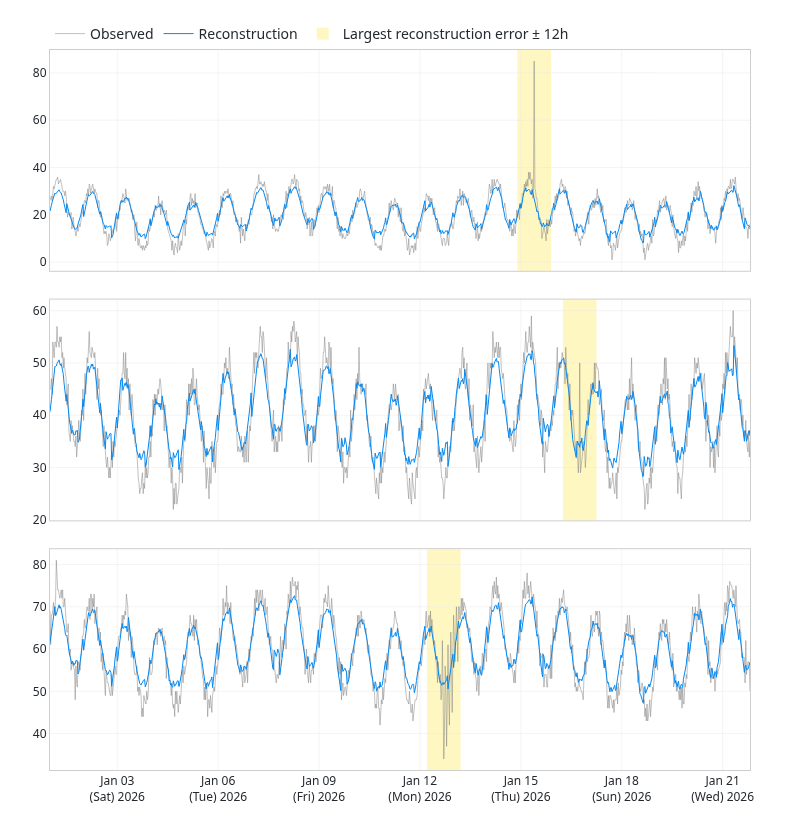

In [17]:
plot(batch_predictions).show()

## 5. Perform real-time inference

Create the endpoint configuration.

In [18]:
endpoint_config = EndpointConfig.create(
    endpoint_config_name=f"moment-endpoint-config-{suffix}",
    production_variants=[
        ProductionVariant(
            variant_name="AllTraffic",
            model_name=model.model_name,
            instance_type=instance_type,
            initial_instance_count=1,
        )
    ],
)

Create the endpoint.

In [19]:
endpoint = Endpoint.create(
    endpoint_name=f"moment-endpoint-{suffix}",
    endpoint_config_name=endpoint_config.endpoint_config_name,
)

Wait for the endpoint to be in service.

In [20]:
session.sagemaker_client.get_waiter("endpoint_in_service").wait(EndpointName=endpoint.endpoint_name)

Invoke the endpoint.

In [21]:
response = endpoint.invoke(
    body=request,
    content_type="text/csv",
    accept="text/csv",
)

Extract the predictions from the response.

In [22]:
real_time_predictions = response.body.read().decode()

real_time_predictions = pd.read_csv(
    io.StringIO(real_time_predictions),
    parse_dates=["timestamp"]
)

In [23]:
real_time_predictions.shape

(3000, 4)

In [24]:
real_time_predictions.head()

,id,timestamp,value,reconstruction
0,A,2026-01-01 00:00:00,26,21.563078
1,A,2026-01-01 00:30:00,28,22.405014
2,A,2026-01-01 01:00:00,28,24.021660
3,A,2026-01-01 01:30:00,26,25.359512
4,A,2026-01-01 02:00:00,32,26.599537


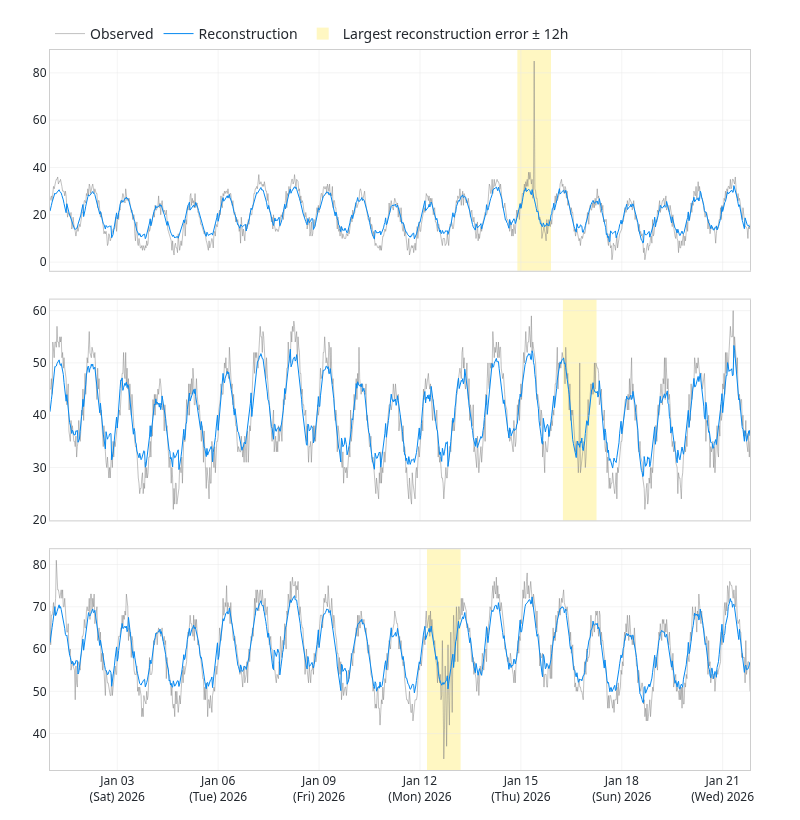

In [25]:
plot(real_time_predictions).show()

Check that the batch and real-time predictions match.

In [26]:
(batch_predictions["reconstruction"] - real_time_predictions["reconstruction"]).abs().max()

np.float64(1.5000000004761205e-05)

Delete the endpoint.

In [27]:
endpoint.delete()

Delete the endpoint configuration.

In [28]:
endpoint_config.delete()

## 6. Perform asynchronous inference

Create the endpoint configuration, with the S3 paths where the endpoint writes the predictions and the errors.

In [29]:
async_endpoint_config = EndpointConfig.create(
    endpoint_config_name=f"moment-async-endpoint-config-{suffix}",
    production_variants=[
        ProductionVariant(
            variant_name="AllTraffic",
            model_name=model.model_name,
            instance_type=instance_type,
            initial_instance_count=1,
        )
    ],
    async_inference_config=AsyncInferenceConfig(
        output_config=AsyncInferenceOutputConfig(
            s3_output_path=f"s3://{bucket}/async_predictions",
            s3_failure_path=f"s3://{bucket}/async_failures",
        )
    ),
)

Create the endpoint.

In [30]:
async_endpoint = Endpoint.create(
    endpoint_name=f"moment-async-endpoint-{suffix}",
    endpoint_config_name=async_endpoint_config.endpoint_config_name,
)

Wait for the endpoint to be in service.

In [31]:
session.sagemaker_client.get_waiter("endpoint_in_service").wait(EndpointName=async_endpoint.endpoint_name)

Invoke the endpoint with the S3 URI of the request, and get the S3 URI where the predictions will be written.

In [32]:
async_response = async_endpoint.invoke_async(
    input_location=data,
    content_type="text/csv",
    accept="text/csv",
)

In [33]:
async_response.output_location

's3://sagemaker-moment-anomaly-detection/async_predictions/b2942358-81df-48e7-bac4-75a650f51ce7.out'

Wait for the predictions, or for the error, to be written to S3.

In [34]:
def s3_exists(s3_uri):
    bucket_name, key = s3_uri.removeprefix("s3://").split("/", 1)
    return key in session.list_s3_files(bucket=bucket_name, key_prefix=key)

while not s3_exists(async_response.output_location):
    if s3_exists(async_response.failure_location):
        raise RuntimeError(f"Asynchronous inference failed, see {async_response.failure_location}")
    time.sleep(10)

Load the predictions from S3.

In [35]:
async_predictions = session.read_s3_file(
    bucket=bucket, 
    key_prefix=async_response.output_location.removeprefix(f"s3://{bucket}/")
)

async_predictions = pd.read_csv(
    io.StringIO(async_predictions),
    parse_dates=["timestamp"]
)

In [36]:
async_predictions.shape

(3000, 4)

In [37]:
async_predictions.head()

,id,timestamp,value,reconstruction
0,A,2026-01-01 00:00:00,26,21.563078
1,A,2026-01-01 00:30:00,28,22.405014
2,A,2026-01-01 01:00:00,28,24.021660
3,A,2026-01-01 01:30:00,26,25.359512
4,A,2026-01-01 02:00:00,32,26.599537


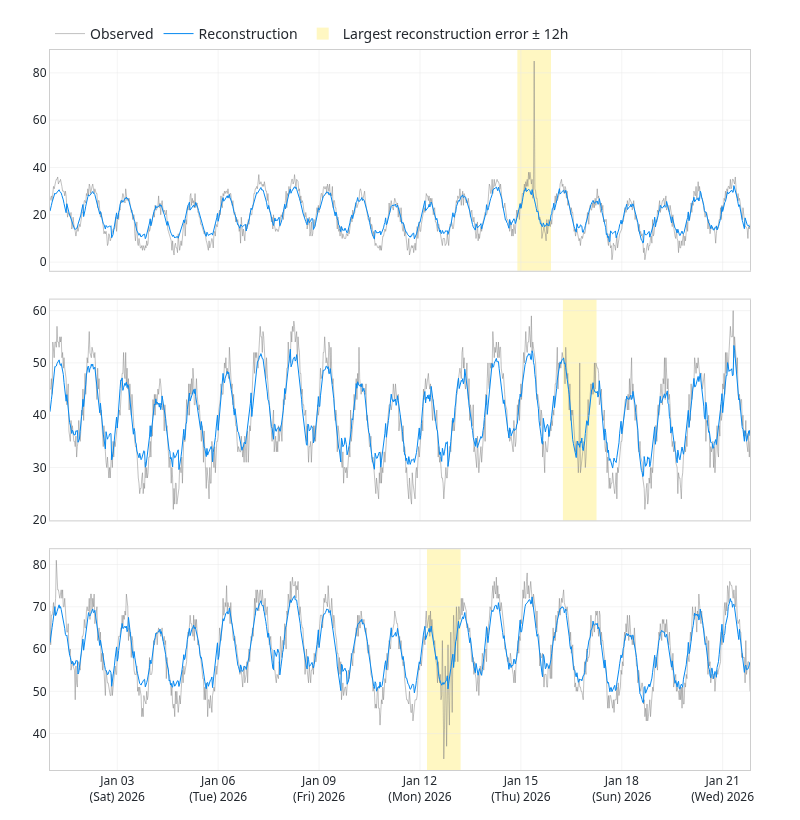

In [38]:
plot(async_predictions).show()

Check that the batch and asynchronous predictions match.

In [39]:
(batch_predictions["reconstruction"] - async_predictions["reconstruction"]).abs().max()

np.float64(1.5000000004761205e-05)

Delete the endpoint.

In [40]:
async_endpoint.delete()

Delete the endpoint configuration.

In [41]:
async_endpoint_config.delete()

## 7. Clean up

Delete the model.

In [42]:
model.delete()